In [105]:

import os

# Location of  dataset
data_folder = r"C:\Users\Lenovo\Downloads\AVIRIS_Forest_Data"

# File paths
hdr_path = os.path.join(
    data_folder,
    "ang20220819t193834_rfl_v2aa2_img.hdr"
)

image_path = os.path.join(
    data_folder,
    "ang20220819t193834_rfl_v2aa2_img"
)

# Check whether the files exist
print("Header file exists:", os.path.exists(hdr_path))
print("Image file exists:", os.path.exists(image_path))

if os.path.exists(image_path):
    print("Image file size:",
          round(os.path.getsize(image_path) / (1024**3), 2), "GB")


Header file exists: True
Image file exists: True
Image file size: 4.22 GB


In [106]:
import spectral
#Open the ENVI image
img=spectral.open_image(hdr_path)
#Displaying image iinformation

print("Image dimensions:", img.shape)
print("Number of rows:", img.nrows)
print("Number of columns:",img.ncols )
print("Number of spectral bands:", img.nbands )
print("Data type:", img.dtype)
print("Interleave:",img.metadata.get("interleave"))


Image dimensions: (3974, 670, 425)
Number of rows: 3974
Number of columns: 670
Number of spectral bands: 425
Data type: <f4
Interleave: bil


Red band: 54 647.6656495000001 nm
Green band: 35 552.4956495 nm
Blue band: 15 452.3256495 nm


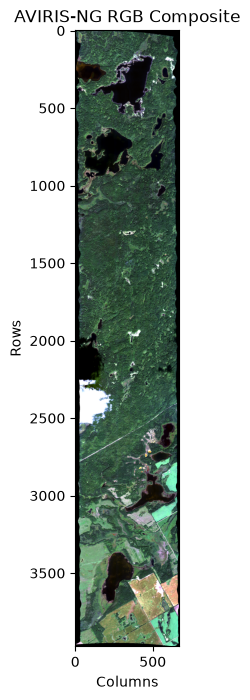

In [107]:

import numpy as np
import matplotlib.pyplot as plt

# Read wavelength information from the header
wavelengths = np.array(
    [float(w) for w in img.metadata["wavelength"]]
)

# Find the closest spectral bands
red_band = np.argmin(abs(wavelengths - 650))
green_band = np.argmin(abs(wavelengths - 550))
blue_band = np.argmin(abs(wavelengths - 450))

print("Red band:", red_band, wavelengths[red_band], "nm")
print("Green band:", green_band, wavelengths[green_band], "nm")
print("Blue band:", blue_band, wavelengths[blue_band], "nm")

# Read only the three selected bands
red = img.read_band(red_band)
green = img.read_band(green_band)
blue = img.read_band(blue_band)

# Combine into RGB
rgb = np.dstack((red, green, blue))

# Remove invalid pixels for contrast calculation
valid = np.all(np.isfinite(rgb) & (rgb != -9999), axis=2)

# Stretch each channel for display
rgb_display = np.zeros_like(rgb, dtype=np.float32)

for i in range(3):
    channel = rgb[:, :, i]
    values = channel[valid]

    low, high = np.percentile(values, [2, 98])

    rgb_display[:, :, i] = np.clip(
        (channel - low) / (high - low), 0, 1
    )

rgb_display[~valid] = 0

# Display
plt.figure(figsize=(12, 8))
plt.imshow(rgb_display)
plt.title("AVIRIS-NG RGB Composite")
plt.xlabel("Columns")
plt.ylabel("Rows")
plt.axis("on")
plt.show()


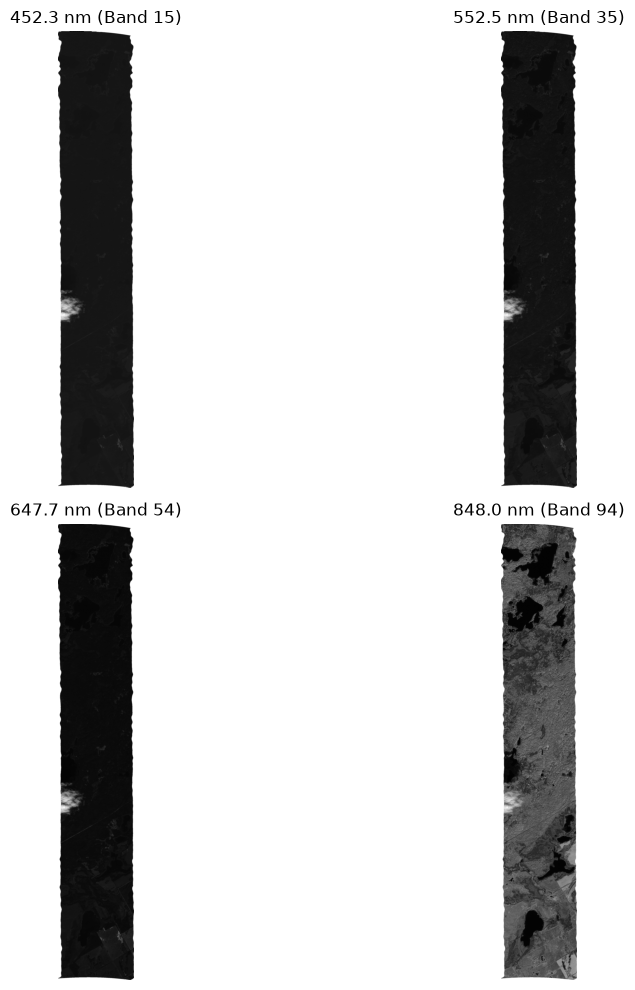

In [108]:

# Wavelengths we want to investigate
selected_wavelengths = [450, 550, 650, 850]

fig, axes = plt.subplots(2, 2, figsize=(13, 10))

for ax, wavelength in zip(axes.flatten(), selected_wavelengths):

    band_index = np.argmin(abs(wavelengths - wavelength))
    band_data = img.read_band(band_index)

    # Mask invalid values
    band_data = np.where(band_data == -9999, np.nan, band_data)

    ax.imshow(band_data, cmap="gray")
    ax.set_title(
        f"{wavelengths[band_index]:.1f} nm (Band {band_index})"
    )
    ax.axis("off")

plt.tight_layout()
plt.show()


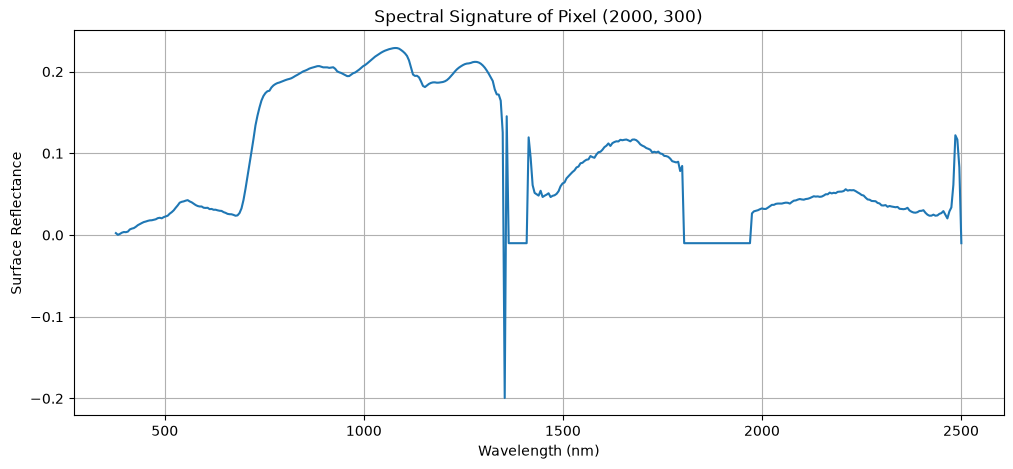

In [109]:
#import random
# Select a sample pixel
row = 2000
col = 300

# Read its reflectance across all 425 bands
pixel_spectrum = img.read_pixel(row, col)

# Remove invalid measurements
valid_bands = (
    np.isfinite(pixel_spectrum) &
    (pixel_spectrum != -9999)
)

plt.figure(figsize=(12, 5))

plt.plot(
    wavelengths[valid_bands],
    pixel_spectrum[valid_bands]
)

plt.xlabel("Wavelength (nm)")
plt.ylabel("Surface Reflectance")
plt.title(f"Spectral Signature of Pixel ({row}, {col})")
plt.grid(True)
plt.show()

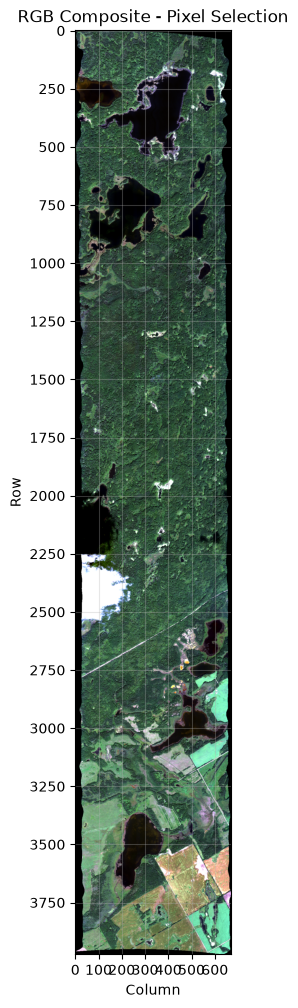

In [110]:
plt.figure(figsize=(10, 12))

plt.imshow(rgb_display)
plt.title("RGB Composite - Pixel Selection")
plt.xlabel("Column")
plt.ylabel("Row")

plt.xticks(np.arange(0, 671, 100))
plt.yticks(np.arange(0, 3975, 250))
plt.grid(alpha=0.3)

plt.show()

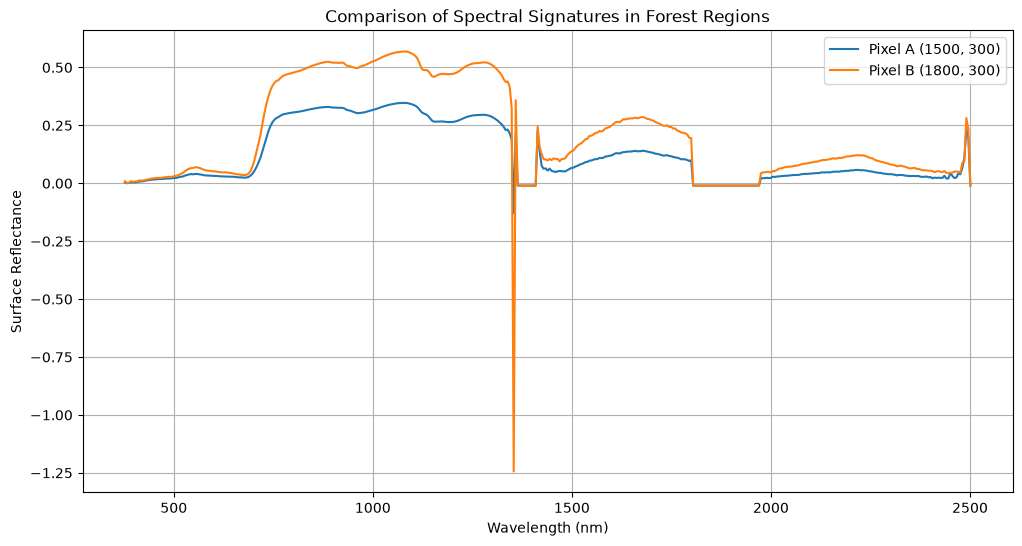

In [111]:
pixel_A = img.read_pixel(1500, 300)
pixel_B = img.read_pixel(1800, 300)

valid_A = np.isfinite(pixel_A) & (pixel_A != -9999)
valid_B = np.isfinite(pixel_B) & (pixel_B != -9999)

plt.figure(figsize=(12, 6))

plt.plot(
    wavelengths[valid_A],
    pixel_A[valid_A],
    label="Pixel A (1500, 300)"
)

plt.plot(
    wavelengths[valid_B],
    pixel_B[valid_B],
    label="Pixel B (1800, 300)"
)

plt.xlabel("Wavelength (nm)")
plt.ylabel("Surface Reflectance")
plt.title("Comparison of Spectral Signatures in Forest Regions")
plt.legend()
plt.grid(True)

plt.show()

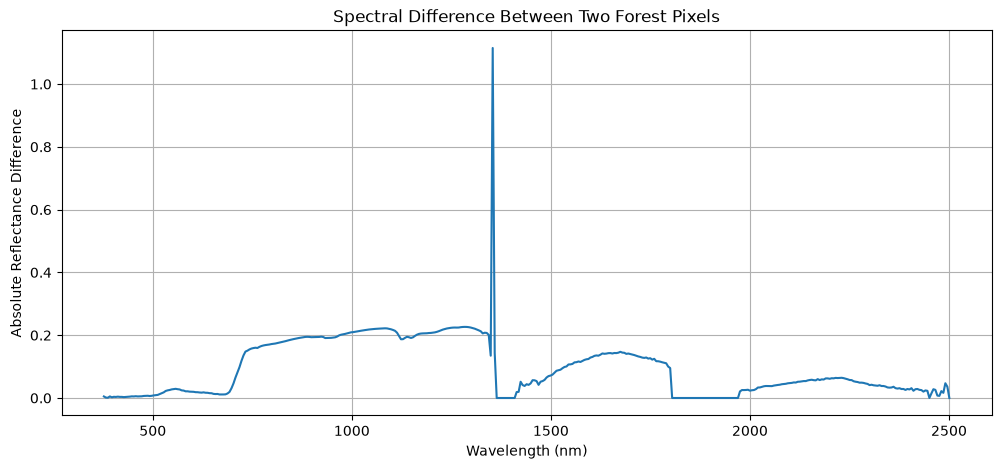

In [112]:
# Calculate absolute difference
difference = np.abs(pixel_A - pixel_B)

# Exclude invalid values
valid = (
    np.isfinite(pixel_A) &
    np.isfinite(pixel_B) &
    (pixel_A != -9999) &
    (pixel_B != -9999)
)

plt.figure(figsize=(12, 5))

plt.plot(
    wavelengths[valid],
    difference[valid]
)

plt.xlabel("Wavelength (nm)")
plt.ylabel("Absolute Reflectance Difference")
plt.title("Spectral Difference Between Two Forest Pixels")
plt.grid(True)

plt.show()

In [113]:
mean_difference = np.mean(difference[valid])

print("Mean absolute reflectance difference:", mean_difference)

Mean absolute reflectance difference: 0.09388819


In [114]:
bbl = np.array(img.metadata["bbl"], dtype=int)

print("Total spectral bands:", len(bbl))
print("Good bands:", np.sum(bbl == 1))
print("Bad bands:", np.sum(bbl == 0))

bad_band_indices = np.where(bbl == 0)[0]

print("Bad band indices:")
print(bad_band_indices)

Total spectral bands: 425
Good bands: 380
Bad bands: 45
Bad band indices:
[197 198 199 200 201 202 203 204 205 206 285 286 287 288 289 290 291 292
 293 294 295 296 297 298 299 300 301 302 303 304 305 306 307 308 309 310
 311 312 313 314 315 316 317 318 424]


In [115]:
bad_wavelengths = wavelengths[bad_band_indices]

print("Bad band wavelengths (nm):")
print(bad_wavelengths)

Bad band wavelengths (nm):
[1363.9056495 1368.9156495 1373.9256495 1378.9256495 1383.9356495
 1388.9456495 1393.9556495 1398.9656495 1403.9756495 1408.9856495
 1804.6656495 1809.6756495 1814.6856495 1819.6956495 1824.7056495
 1829.7056495 1834.7156495 1839.7256495 1844.7356495 1849.7456495
 1854.7556495 1859.7656495 1864.7756495 1869.7756495 1874.7856495
 1879.7956495 1884.8056495 1889.8156495 1894.8256495 1899.8356495
 1904.8356495 1909.8456495 1914.8556495 1919.8656495 1924.8756495
 1929.8856495 1934.8956495 1939.9056495 1944.9056495 1949.9156495
 1954.9256495 1959.9356495 1964.9456495 1969.9556495 2500.8756495]


In [116]:
# Identify good spectral bands
good_band_mask = (bbl == 1)

# Extract wavelengths of good bands
good_wavelengths = wavelengths[good_band_mask]

print("Total good bands:", len(good_wavelengths))
print("First 10 good wavelengths:")
print(good_wavelengths[:10])

print("\nLast 10 good wavelengths:")
print(good_wavelengths[-10:])

Total good bands: 380
First 10 good wavelengths:
[377.1956495 382.2056495 387.2156495 392.2256495 397.2256495 402.2356495
 407.2456495 412.2556495 417.2656495 422.2756495]

Last 10 good wavelengths:
[2450.7856495 2455.7956495 2460.8056495 2465.8156495 2470.8156495
 2475.8256495 2480.8356495 2485.8456495 2490.8556495 2495.8656495]


In [117]:
# Create a list of indices corresponding to good bands
good_band_indices = np.where(bbl == 1)[0]


# Select a smaller region
row_start = 1400
row_end = 1900

col_start = 100
col_end = 600

# Extract only good bands from this region
clean_img = img.read_subregion(
    (row_start, row_end),
    (col_start, col_end),
    bands=good_band_indices
)

print("Clean image dimensions:", clean_img.shape)
print("Number of spectral bands:", clean_img.shape[2])

Clean image dimensions: (500, 500, 380)
Number of spectral bands: 380


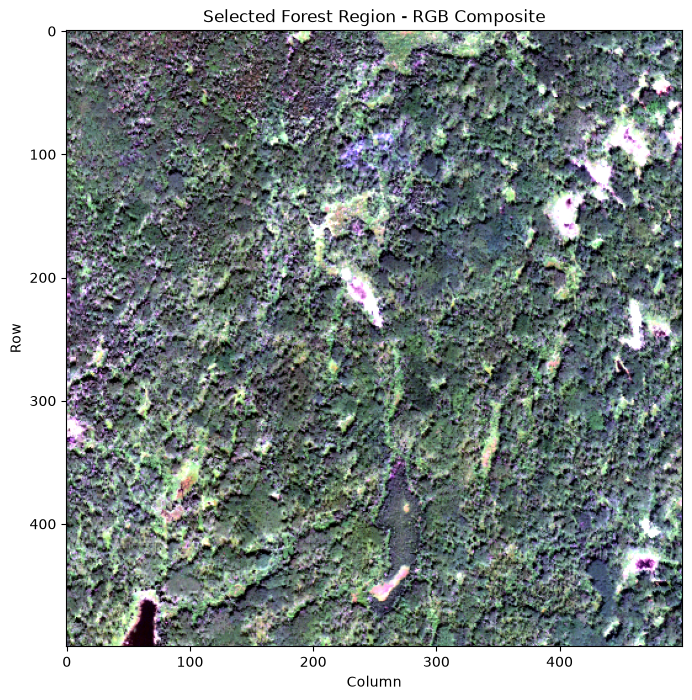

In [118]:
# Generate RGB composite for the selected region

red_index = np.argmin(abs(good_wavelengths - 650))
green_index = np.argmin(abs(good_wavelengths - 550))
blue_index = np.argmin(abs(good_wavelengths - 450))

rgb_subset = clean_img[:, :, [red_index, green_index, blue_index]]

# Mask invalid pixels
valid_pixels = np.all(
    np.isfinite(rgb_subset) & (rgb_subset != -9999),
    axis=2
)

rgb_display_subset = np.zeros_like(rgb_subset, dtype=np.float32)

for i in range(3):
    channel = rgb_subset[:, :, i]
    values = channel[valid_pixels]

    low, high = np.percentile(values, [2, 98])

    rgb_display_subset[:, :, i] = np.clip(
        (channel - low) / (high - low),
        0, 1
    )

rgb_display_subset[~valid_pixels] = 0

plt.figure(figsize=(9, 8))
plt.imshow(rgb_display_subset)
plt.title("Selected Forest Region - RGB Composite")
plt.xlabel("Column")
plt.ylabel("Row")
plt.show()

In [119]:
# Convert invalid measurements to NaN
data = clean_img.astype(np.float32)

data[
    (~np.isfinite(data)) | (data == -9999)
] = np.nan

# Calculate mean and standard deviation for each band
mean_spectrum = np.nanmean(data, axis=(0, 1))

std_spectrum = np.nanstd(data, axis=(0, 1))

print("Mean spectrum shape:", mean_spectrum.shape)
print("Standard deviation shape:", std_spectrum.shape)

Mean spectrum shape: (380,)
Standard deviation shape: (380,)


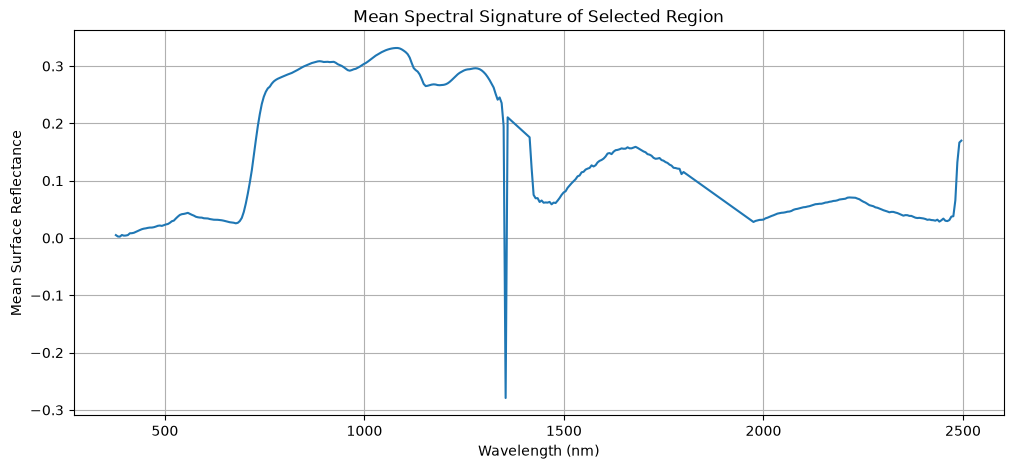

In [120]:
plt.figure(figsize=(12, 5))

plt.plot(good_wavelengths, mean_spectrum)

plt.xlabel("Wavelength (nm)")
plt.ylabel("Mean Surface Reflectance")
plt.title("Mean Spectral Signature of Selected Region")

plt.grid(True)
plt.show()

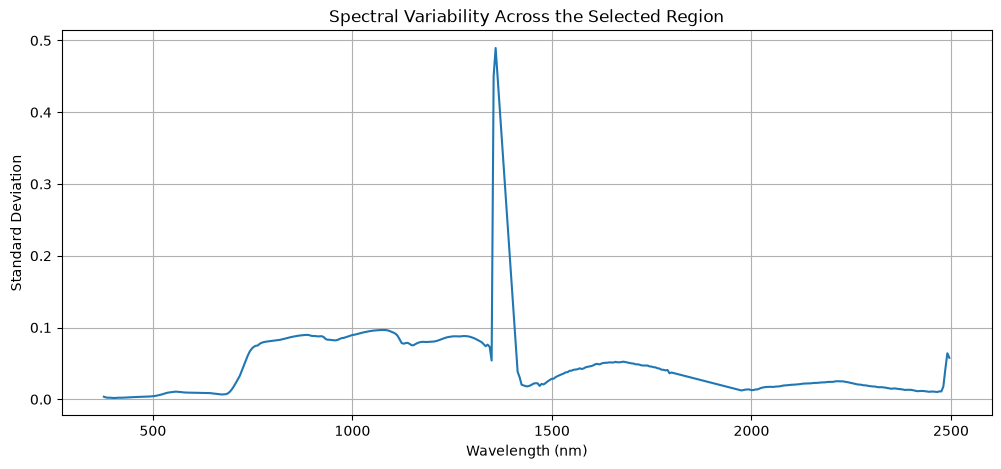

In [121]:
plt.figure(figsize=(12, 5))

plt.plot(good_wavelengths, std_spectrum)

plt.xlabel("Wavelength (nm)")
plt.ylabel("Standard Deviation")
plt.title("Spectral Variability Across the Selected Region")

plt.grid(True)
plt.show()

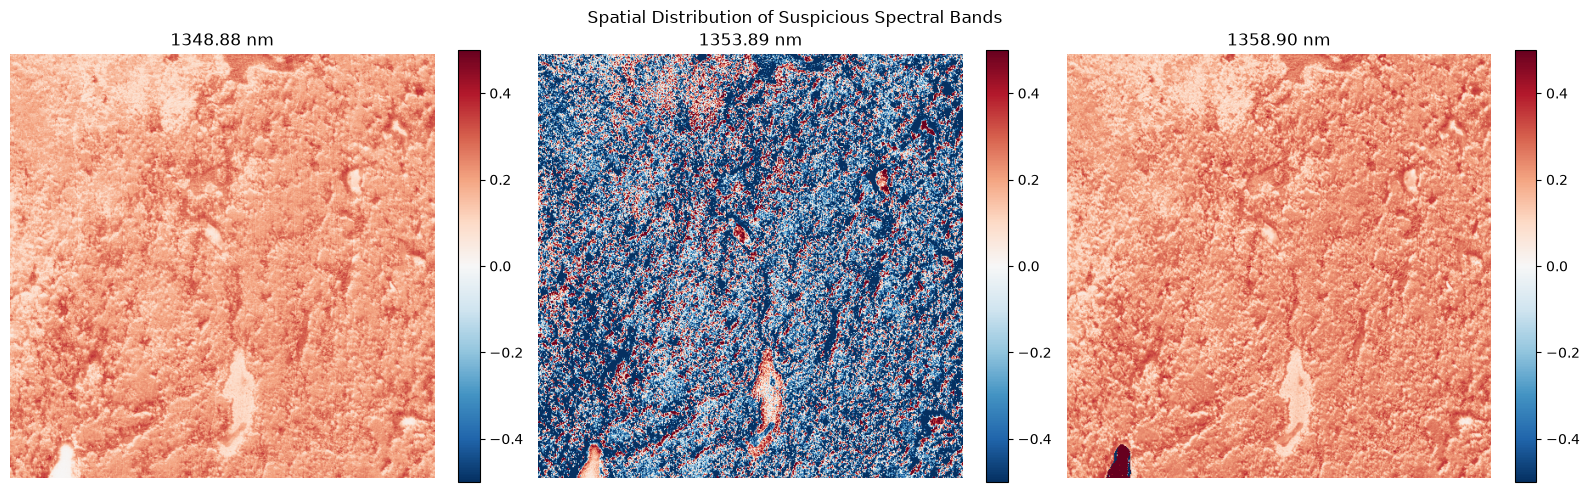

In [122]:
test_wavelengths = [1348.89, 1353.89, 1358.90]

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, wl in zip(axes, test_wavelengths):

    band_index = np.argmin(abs(good_wavelengths - wl))
    band = data[:, :, band_index]

    im = ax.imshow(
        band,
        cmap="RdBu_r",
        vmin=-0.5,
        vmax=0.5
    )

    ax.set_title(f"{good_wavelengths[band_index]:.2f} nm")
    ax.axis("off")
    plt.colorbar(im, ax=ax, fraction=0.046)

plt.suptitle("Spatial Distribution of Suspicious Spectral Bands")
plt.tight_layout()
plt.show()

In [123]:
# Start with the provider's good-band mask
final_band_mask = (bbl == 1)

# Exclude additional suspicious wavelengths
suspicious_wavelengths = [1353.89, 1358.90]

for wl in suspicious_wavelengths:
    index = np.argmin(abs(wavelengths - wl))
    final_band_mask[index] = False

# Extract final wavelengths and indices
final_band_indices = np.where(final_band_mask)[0]
final_wavelengths = wavelengths[final_band_mask]

print("Original bands:", len(wavelengths))
print("Provider-approved bands:", np.sum(bbl == 1))
print("Additional bands excluded:", 2)
print("Final usable bands:", len(final_band_indices))

Original bands: 425
Provider-approved bands: 380
Additional bands excluded: 2
Final usable bands: 378


In [124]:
# Extract the final selected spectral bands
final_img = img.read_subregion(
    (row_start, row_end),
    (col_start, col_end),
    bands=final_band_indices
)

print("Final image dimensions:", final_img.shape)
print("Number of spectral bands:", final_img.shape[2])
print("Number of pixels:", final_img.shape[0] * final_img.shape[1])

Final image dimensions: (500, 500, 378)
Number of spectral bands: 378
Number of pixels: 250000


In [125]:
# Identify pixels containing invalid measurements
valid_measurements = (
    np.isfinite(final_img) &
    (final_img != -9999)
)

valid_pixels = np.all(valid_measurements, axis=2)

print("Total pixels:", valid_pixels.size)
print("Completely valid pixels:", np.sum(valid_pixels))
print("Pixels containing invalid measurements:", np.sum(~valid_pixels))
print("Valid pixel percentage:", np.mean(valid_pixels) * 100)

Total pixels: 250000
Completely valid pixels: 250000
Pixels containing invalid measurements: 0
Valid pixel percentage: 100.0


In [126]:
# Convert final image to float32
final_data = final_img.astype(np.float32)

# Calculate mean spectrum of the entire region
background_mean = np.mean(final_data, axis=(0, 1))

print("Background mean shape:", background_mean.shape)
print("Number of spectral features:", len(background_mean))

Background mean shape: (378,)
Number of spectral features: 378


In [127]:
# Create an empty anomaly score image
anomaly_scores = np.zeros((500, 500), dtype=np.float32)

# Process 50 rows at a time
for start in range(0, 500, 50):

    end = start + 50

    # Extract a small block
    block = final_data[start:end, :, :]

    # Calculate spectral distance from background mean
    difference = block - background_mean

    scores = np.sqrt(
        np.sum(difference ** 2, axis=2)
    )

    # Store scores
    anomaly_scores[start:end, :] = scores

print("Anomaly score image shape:", anomaly_scores.shape)
print("Minimum anomaly score:", np.min(anomaly_scores))
print("Maximum anomaly score:", np.max(anomaly_scores))
print("Mean anomaly score:", np.mean(anomaly_scores))

Anomaly score image shape: (500, 500)
Minimum anomaly score: 0.04308405
Maximum anomaly score: 3.532518
Mean anomaly score: 0.86984575


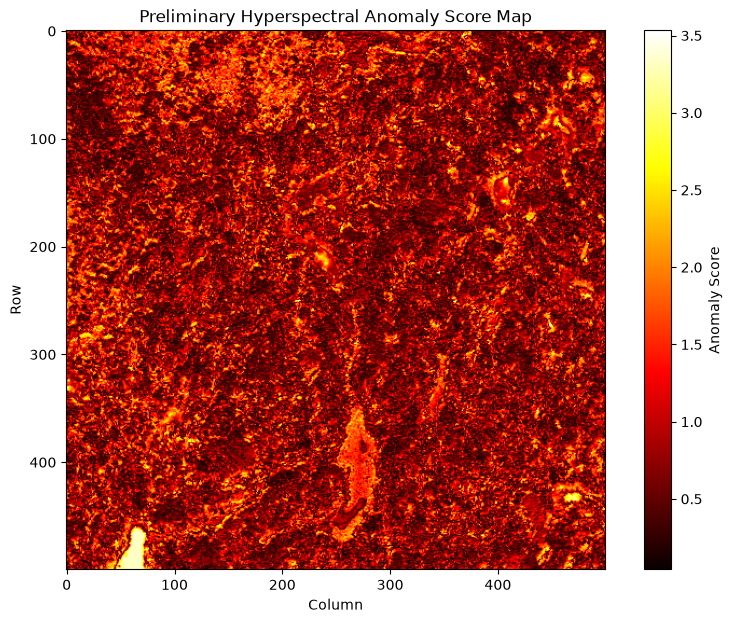

In [128]:
plt.figure(figsize=(10, 7))

plt.imshow(anomaly_scores, cmap="hot")
plt.colorbar(label="Anomaly Score")

plt.title("Preliminary Hyperspectral Anomaly Score Map")
plt.xlabel("Column")
plt.ylabel("Row")

plt.show()

In [129]:
# Calculate the threshold for the top 1% anomaly scores
threshold = np.percentile(anomaly_scores, 99)

# Identify pixels above the threshold
anomaly_mask = anomaly_scores >= threshold

print("Anomaly threshold:", threshold)
print("Detected anomaly pixels:", np.sum(anomaly_mask))
print("Percentage of detected pixels:",
      np.mean(anomaly_mask) * 100)

Anomaly threshold: 2.39187
Detected anomaly pixels: 2500
Percentage of detected pixels: 1.0


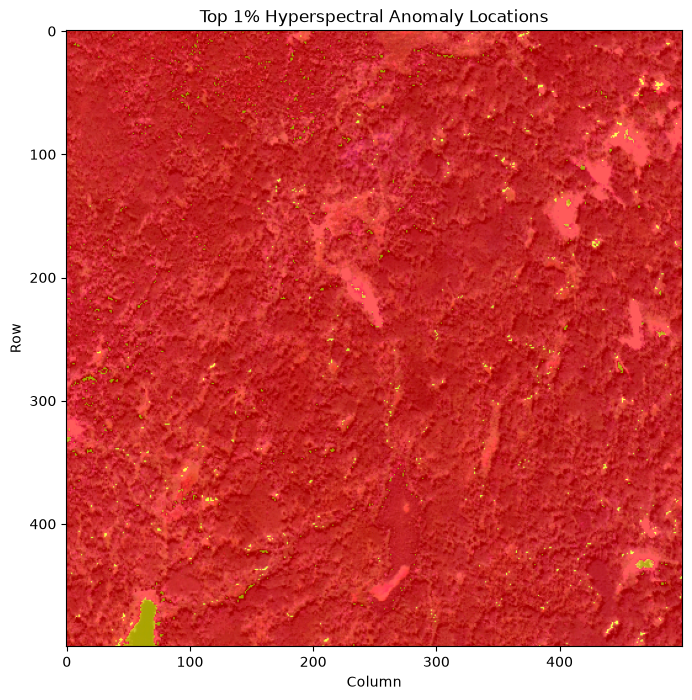

In [130]:
plt.figure(figsize=(10, 8))

plt.imshow(rgb_display_subset)

plt.imshow(
    anomaly_mask,
    cmap="autumn",
    alpha=0.65
)

plt.title("Top 1% Hyperspectral Anomaly Locations")
plt.xlabel("Column")
plt.ylabel("Row")

plt.show()

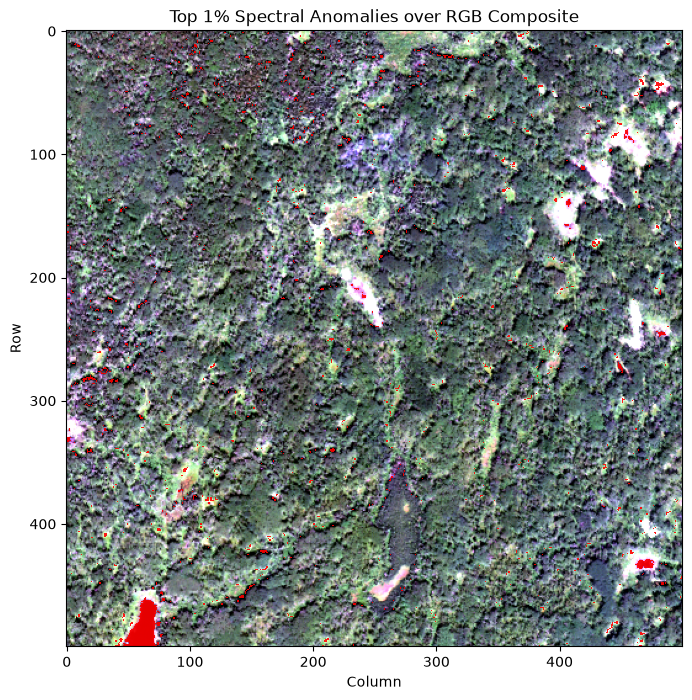

In [131]:
# Make non-anomaly pixels transparent
anomaly_overlay = np.ma.masked_where(
    ~anomaly_mask,
    anomaly_mask
)

plt.figure(figsize=(10, 8))

plt.imshow(rgb_display_subset)

plt.imshow(
    anomaly_overlay,
    cmap="autumn",
    alpha=0.9,
    interpolation="nearest"
)

plt.title("Top 1% Spectral Anomalies over RGB Composite")
plt.xlabel("Column")
plt.ylabel("Row")

plt.show()